In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")

In [ ]:
df = pd.read_csv(
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [ ]:
print(df.isnull().sum().sum())

0


In [ ]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [ ]:
print(df["Attrition"].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [ ]:
df_clean = df.copy()

columns_to_drop = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

df_clean.drop(
    columns=columns_to_drop,
    inplace=True
)

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (1470, 31)


In [ ]:
df_clean.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [ ]:
# Count employees who left and stayed
print(df_clean["Attrition"].value_counts())

# Calculate attrition percentage
attrition_rate = (
    df_clean["Attrition"].value_counts(normalize=True) * 100
)

print("\nAttrition Percentage:")
print(attrition_rate)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


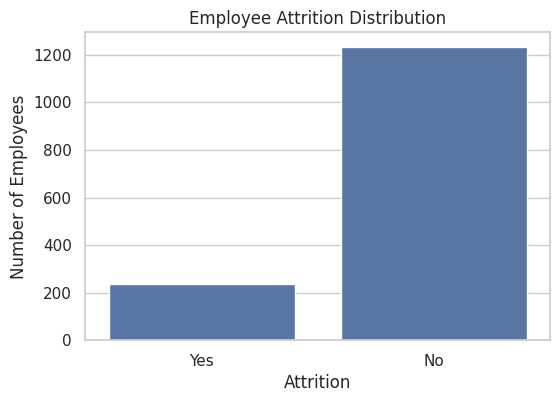

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_clean,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

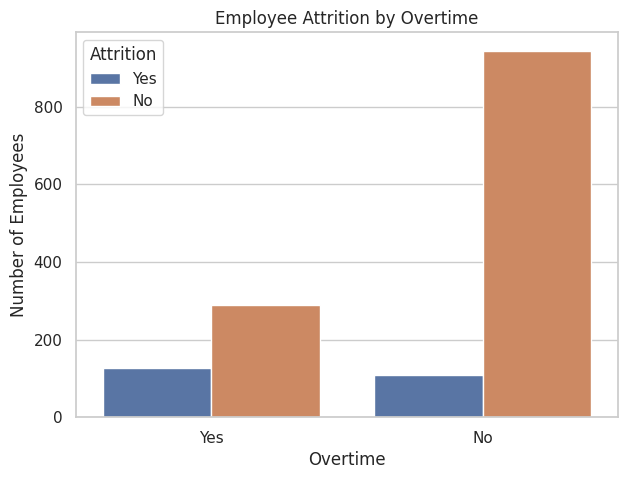

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:
overtime_rate = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print(overtime_rate.round(2))

Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53


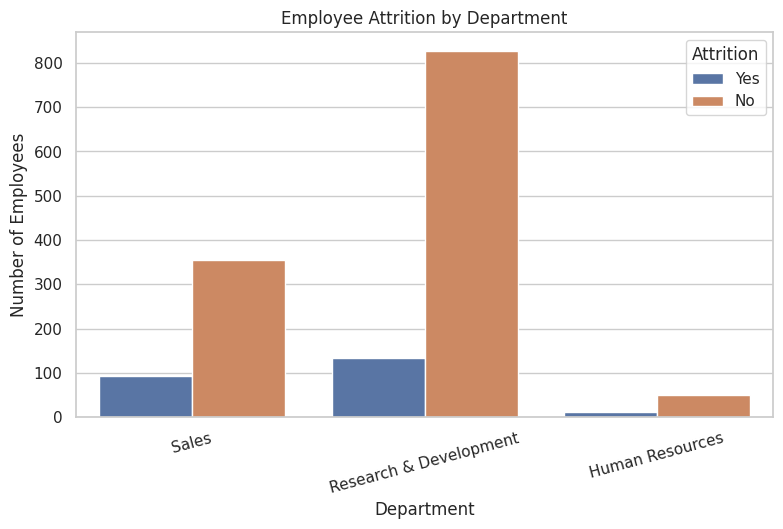

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)

plt.show()

In [ ]:
department_rate = pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print(department_rate.round(2))

Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63


In [ ]:
department_attrition = (
    department_rate["Yes"]
    .sort_values(ascending=False)
)

print(department_attrition.round(2))

Department
Sales                     20.63
Human Resources           19.05
Research & Development    13.84
Name: Yes, dtype: float64


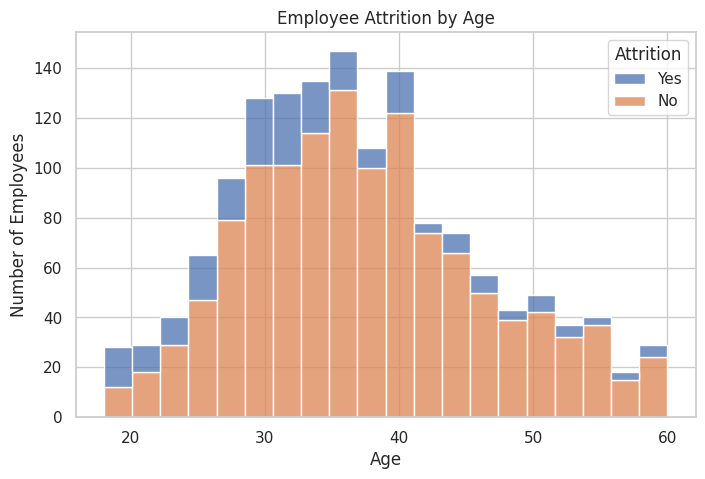

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="Attrition",
    bins=20,
    multiple="stack"
)

plt.title("Employee Attrition by Age")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65"
    ]
)

age_attrition = pd.crosstab(
    df_clean["AgeGroup"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print(age_attrition.round(2))

Attrition     No    Yes
AgeGroup               
18-25      64.23  35.77
26-35      80.86  19.14
36-45      90.81   9.19
46-55      88.50  11.50
56-65      82.98  17.02


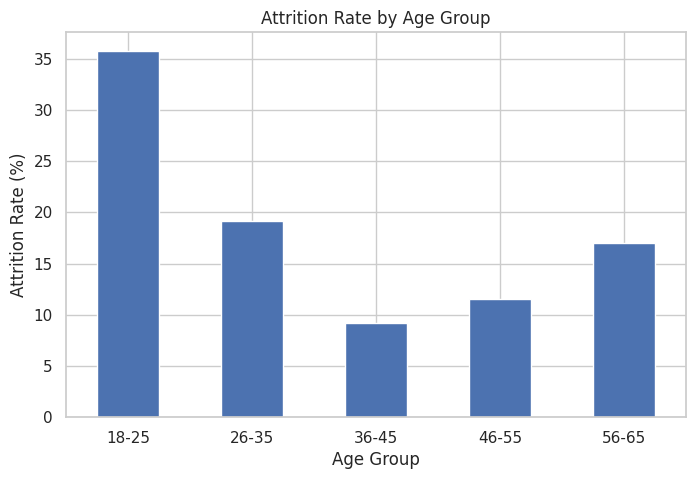

In [ ]:
age_attrition["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

plt.show()

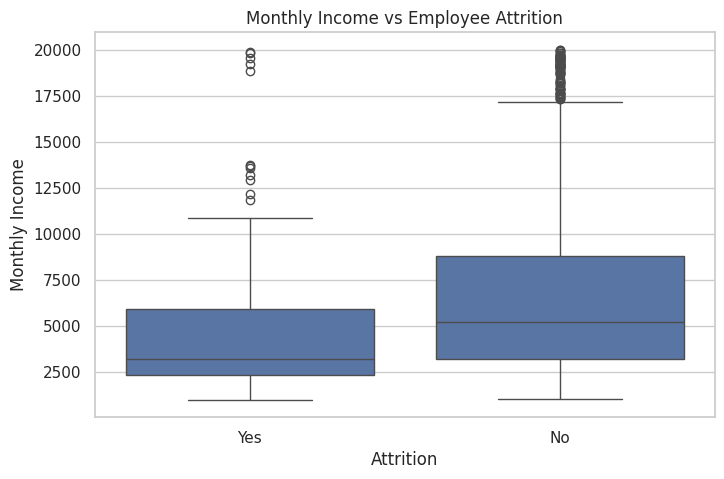

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

In [ ]:
income_analysis = df_clean.groupby(
    "Attrition"
)["MonthlyIncome"].mean()

print(income_analysis)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


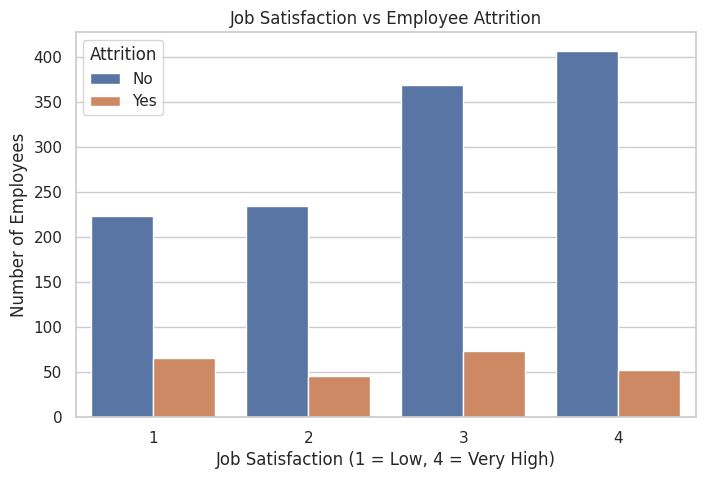

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="JobSatisfaction",
    hue="Attrition"
)

plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:
satisfaction_rate = pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print(satisfaction_rate.round(2))

Attrition           No    Yes
JobSatisfaction              
1                77.16  22.84
2                83.57  16.43
3                83.48  16.52
4                88.67  11.33


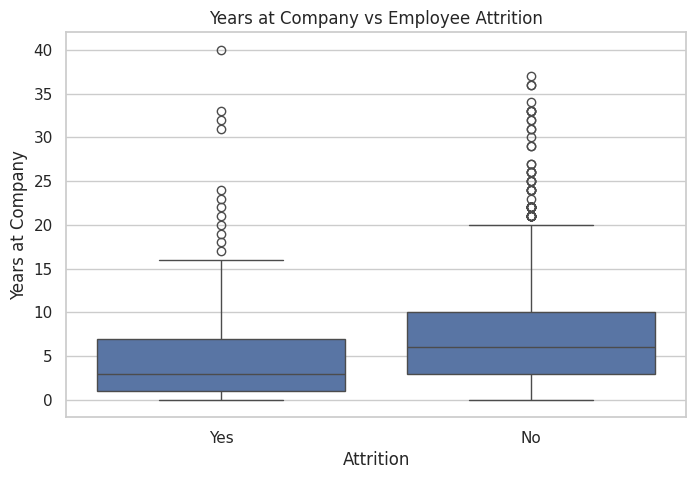

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Years at Company vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

In [ ]:
tenure_analysis = df_clean.groupby(
    "Attrition"
)["YearsAtCompany"].mean()

print(tenure_analysis)

Attrition
No     7.369019
Yes    5.130802
Name: YearsAtCompany, dtype: float64


In [ ]:
satisfaction_rate = pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print(satisfaction_rate.round(2))

Attrition           No    Yes
JobSatisfaction              
1                77.16  22.84
2                83.57  16.43
3                83.48  16.52
4                88.67  11.33


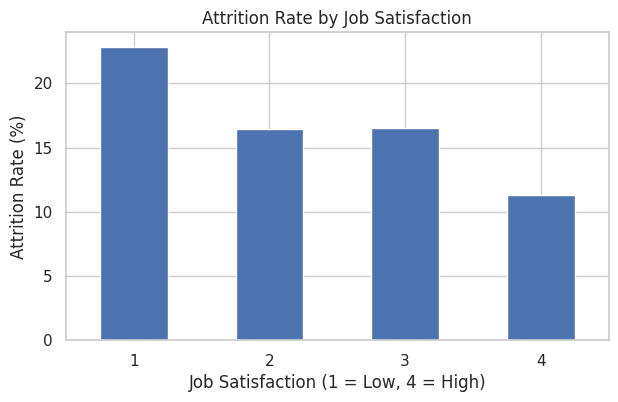

In [ ]:
satisfaction_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Separate input features and target variable

X = df_clean.drop("Attrition", axis=1)

y = df_clean["Attrition"].map({
    "Yes": 1,
    "No": 0
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1470, 31)
Target shape: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1176, 31)
Testing data: (294, 31)


In [ ]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:", len(categorical_features))
print("Numerical columns:", len(numerical_features))

print("\nCategorical features:")
print(categorical_features)

Categorical columns: 7
Numerical columns: 23

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict employee attrition
y_pred_lr = logistic_model.predict(X_test)

# Get probability of attrition
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred_lr[:10])

First 10 predictions: [0 0 0 0 1 1 0 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.7517006802721088
Precision: 0.3488372093023256
Recall: 0.6382978723404256
F1 Score: 0.45112781954887216
ROC-AUC: 0.8031699543457662

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.77      0.84       247
           1       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



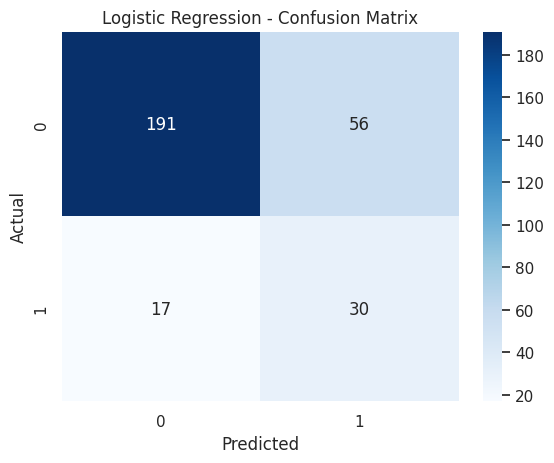

In [ ]:
cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred_rf[:10])

First 10 predictions: [1 0 0 0 0 0 0 0 0 0]


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8435374149659864
Precision: 0.5714285714285714
Recall: 0.0851063829787234
F1 Score: 0.14814814814814814
ROC-AUC: 0.7841330002584201

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.99      0.91       247
           1       0.57      0.09      0.15        47

    accuracy                           0.84       294
   macro avg       0.71      0.54      0.53       294
weighted avg       0.81      0.84      0.79       294



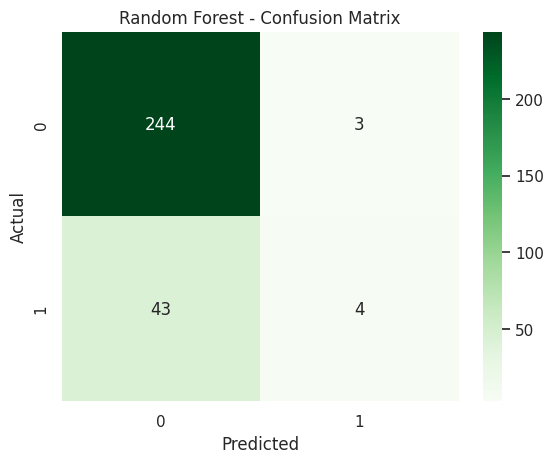

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.752,0.349,0.638,0.451,0.803
1,Random Forest,0.844,0.571,0.085,0.148,0.784


In [ ]:
# Get trained Random Forest classifier
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
importance_df.head(15)

,Feature,Importance
37,numerical__MonthlyIncome,0.069249
28,numerical__Age,0.059431
44,numerical__TotalWorkingYears,0.055548
29,numerical__DailyRate,0.048890
47,numerical__YearsAtCompany,0.045925
50,numerical__YearsWithCurrManager,0.043093
30,numerical__DistanceFromHome,0.041938
38,numerical__MonthlyRate,0.041824
33,numerical__HourlyRate,0.040585
39,numerical__NumCompaniesWorked,0.036104


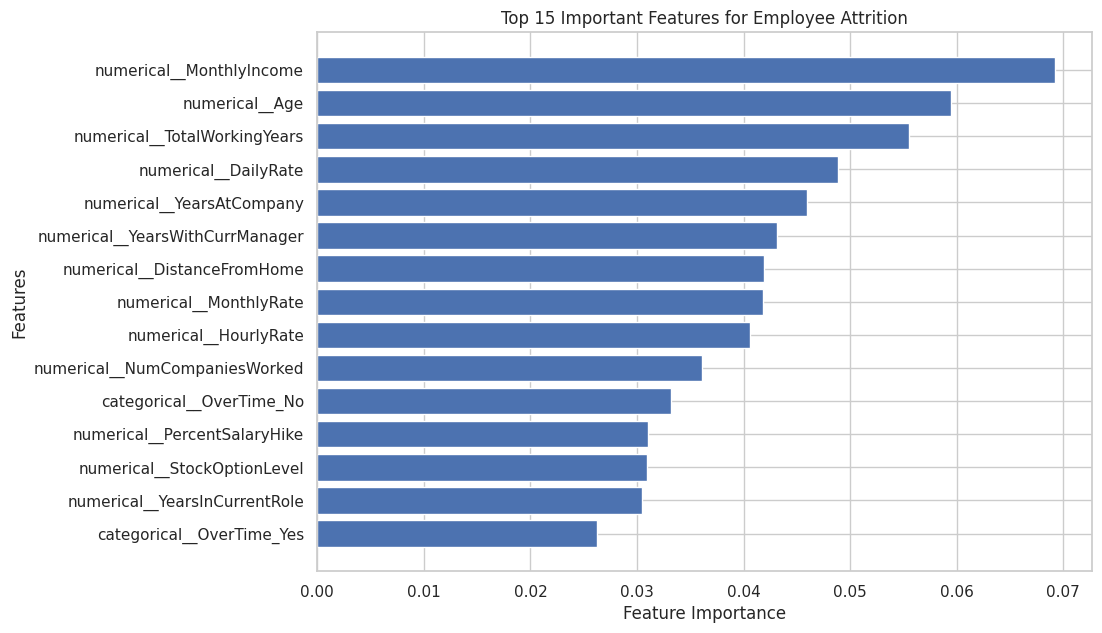

In [ ]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Important Features for Employee Attrition")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()